# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Resolución completa · semilla 42.** Autoría del equipo: no informada.

Se resuelven los pasos 1 a 20 y las siete preguntas de reflexión. Las implementaciones están en `src/` y las pruebas provistas se conservan. Ejecutar desde la carpeta del caso o desde la raíz del proyecto.

**Criterios de trabajo, no requisitos confirmados por Cauce.** El material no incluye valores de aceptación ni enumera los cinco indicadores. Adoptamos: exactitud del clasificador ≥85%, F1 macro ≥85%, cobertura automática ≥70%, exactitud automática ≥95% y fraude perdido ≤2%. Para elegir umbrales exigimos en validación exactitud automática ≥97% y fraude perdido ≤1%, buscando la mayor cobertura. Laura Benítez y los responsables de Fraude deben ratificar estos límites antes de un piloto. El fraude enviado a revisión no se cuenta como perdido en la métrica provista, pero requiere atención urgente.

El conjunto de prueba queda reservado hasta el paso 15. Los hiperparámetros, los umbrales y la elección entre modelos se resuelven con el 80% de entrenamiento. Los resultados describen estos datos; una partición aleatoria no reemplaza una validación temporal ni por cliente.

In [1]:
from pathlib import Path
import sys, subprocess, json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

BASE = Path.cwd()
if not (BASE / 'datos/mensajes_historicos.csv').exists():
    BASE = BASE / 'caso1_cauce'
assert (BASE / 'datos/mensajes_historicos.csv').exists(), 'Ejecutar desde el proyecto o la carpeta del caso'
sys.path.insert(0, str(BASE))
from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion
SEMILLA = 42
FIGURAS = BASE / 'figuras'
FIGURAS.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 130)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False})
print({'Python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__})

def pruebas(archivo=None):
    comando = [sys.executable, '-m', 'pytest', '-q', 'tests' if archivo is None else f'tests/{archivo}']
    resultado = subprocess.run(comando, cwd=BASE, capture_output=True, text=True)
    print(resultado.stdout)
    assert resultado.returncode == 0, resultado.stderr + resultado.stdout

def matriz(y, pred, titulo, archivo):
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=CLASES, normalize='true',
                                            values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
    ax.set(title=titulo, xlabel='Equipo predicho / derivado', ylabel='Equipo real')
    plt.xticks(rotation=35, ha='right')
    fig.tight_layout()
    fig.savefig(FIGURAS / archivo, dpi=150, bbox_inches='tight')
    plt.show()

{'Python': '3.14.7', 'numpy': '2.5.3', 'pandas': '3.0.6', 'sklearn': '1.9.1'}


### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
pruebas()

...............................                                          [100%]
31 passed in 3.44s



## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

In [3]:
historico = pd.read_csv(BASE / 'datos/mensajes_historicos.csv')
CLASES = np.sort(historico.equipo_final.unique())
duplicados = historico.duplicated(['id_cliente', 'texto'])
vacios = historico.texto.fillna('').str.strip().eq('')
print(f'Filas: {len(historico):,}; vacíos o nulos: {vacios.sum()}; duplicados: {duplicados.sum()}')
display(historico.isna().sum().rename('nulos').to_frame())
display(historico.equipo_final.value_counts().to_frame('mensajes').assign(
    porcentaje=lambda d: 100*d.mensajes/len(historico)))
display(historico.canal.value_counts().to_frame('mensajes'))
display(historico.assign(palabras=historico.texto.fillna('').str.split().str.len())
        .groupby('equipo_final').palabras.describe().round(2))

Filas: 8,200; vacíos o nulos: 18; duplicados: 200


,nulos
id_mensaje,0
fecha_hora,0
id_cliente,0
canal,0
texto,11
equipo_derivado,0
equipo_final,0


,mensajes,porcentaje
equipo_final,,
transferencias,2552,31.121951
tarjeta,2057,25.085366
cuenta_acceso,1648,20.097561
prestamos_inversiones,1029,12.548780
fraude,914,11.146341


,mensajes
canal,
app_chat,3676
whatsapp,2499
email,1163
formulario_web,862


,count,mean,std,min,25%,50%,75%,max
equipo_final,,,,,,,,
cuenta_acceso,1648.0,13.87,5.42,0.0,10.0,13.0,17.0,46.0
fraude,914.0,18.22,7.18,0.0,14.0,17.0,22.0,50.0
prestamos_inversiones,1029.0,12.58,4.88,0.0,9.0,12.0,15.0,33.0
tarjeta,2057.0,14.81,5.43,0.0,11.0,14.0,18.0,42.0
transferencias,2552.0,16.95,5.67,0.0,13.0,17.0,20.0,41.0


**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

,proporción
exactitud,0.826098
f1_macro,0.816555
fraude_a_otro_equipo,0.317287


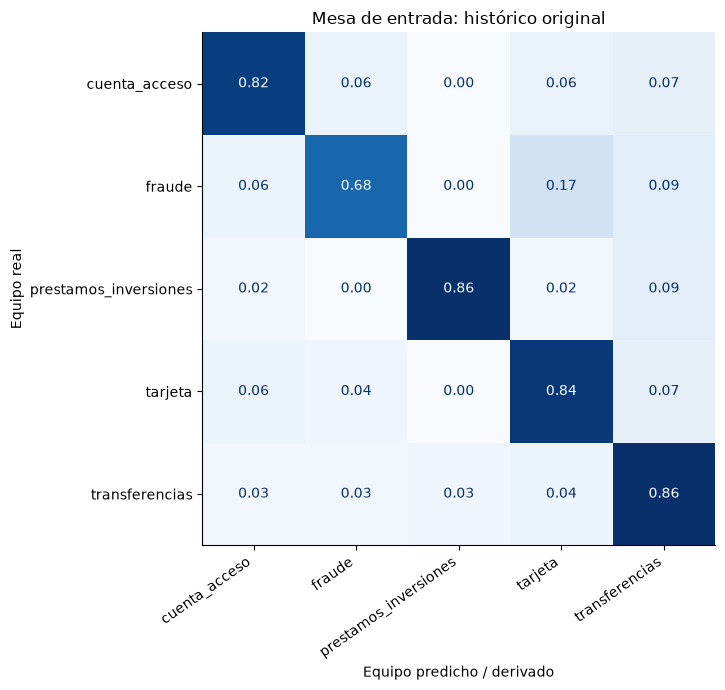

In [4]:
fraude_inicial = historico.equipo_final.eq('fraude')
base_inicial = {
    'exactitud': accuracy_score(historico.equipo_final, historico.equipo_derivado),
    'f1_macro': f1_score(historico.equipo_final, historico.equipo_derivado, average='macro'),
    'fraude_a_otro_equipo': historico.loc[fraude_inicial, 'equipo_derivado'].ne('fraude').mean(),
}
display(pd.Series(base_inicial).to_frame('proporción'))
matriz(historico.equipo_final, historico.equipo_derivado, 'Mesa de entrada: histórico original', 'paso02_mesa.png')

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [5]:
datos = historico.drop_duplicates(['id_cliente', 'texto'], keep='first').copy()
assert not datos.duplicated(['id_cliente', 'texto']).any()
print(f'Se conservan {len(datos):,} mensajes; se eliminan {len(historico)-len(datos)} repeticiones.')
display(Markdown('Se deduplica **antes** de dividir para impedir que una copia del mismo mensaje y cliente '
                 'aparezca en entrenamiento y prueba, inflando la evaluación. Esto no elimina plantillas '
                 'compartidas entre clientes ni garantiza independencia temporal.'))

Se conservan 8,000 mensajes; se eliminan 200 repeticiones.


Se deduplica **antes** de dividir para impedir que una copia del mismo mensaje y cliente aparezca en entrenamiento y prueba, inflando la evaluación. Esto no elimina plantillas compartidas entre clientes ni garantiza independencia temporal.

## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [6]:
pruebas('test_limpieza.py')
ejemplos = pd.Series([
    '¡Me cobraron $ 15.000 y NO los reconozco!',
    'mi DNI es 30.123.456 😡',
    'Entré a https://cauce-premios.xyz/login y escribí a soporte@cauce.com.ar',
    'Pagué Gs. 150.000 y USD 20',
    '  ¡NO puedo entrar a mi cuenta!  ',
], name='original')
display(ejemplos.to_frame().assign(limpio=ejemplos.map(limpiar_texto)))
display(Markdown('Se conserva **no**, porque la negación distingue una compra propia de una desconocida. '
                 'No se aplica una lista de stopwords genérica. Los tokens reducen variaciones de números, montos y enlaces.'))

...............                                                          [100%]
15 passed in 0.05s



,original,limpio
0,¡Me cobraron $ 15.000 y NO los reconozco!,me cobraron _monto_ y no los reconozco
1,mi DNI es 30.123.456 😡,mi dni es _num_
2,Entré a https://cauce-premios.xyz/login y escribí a soporte@cauce.com.ar,entre a _url_ y escribi a _email_
3,Pagué Gs. 150.000 y USD 20,pague _monto_ y _monto_
4,¡NO puedo entrar a mi cuenta!,no puedo entrar a mi cuenta


Se conserva **no**, porque la negación distingue una compra propia de una desconocida. No se aplica una lista de stopwords genérica. Los tokens reducen variaciones de números, montos y enlaces.

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [7]:
datos['texto_limpio'] = datos.texto.map(limpiar_texto)
datos['n_palabras'] = datos.texto_limpio.str.split().str.len()
cortos = datos.loc[datos.n_palabras < 2].copy()
aptos = datos.loc[datos.n_palabras >= 2].copy()
print(f'{len(cortos)} mensajes cortos ({len(cortos)/len(datos):.2%}) van directamente a revisión; {len(aptos)} aptos.')
display(cortos[['texto', 'texto_limpio']].value_counts(dropna=False).rename('cantidad').reset_index())
display(cortos.equipo_final.value_counts().to_frame('cortos_por_equipo'))

70 mensajes cortos (0.88%) van directamente a revisión; 7930 aptos.


,texto,texto_limpio,cantidad
0,?,,14
1,NaN,,11
2,Hola,hola,9
3,.,,7
4,ok,ok,7
5,,,6
6,👍,,6
7,hola,hola,6
8,...,,4


,cortos_por_equipo
equipo_final,
tarjeta,18
transferencias,16
cuenta_acceso,16
prestamos_inversiones,14
fraude,6


## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [8]:
pruebas('test_naive_bayes.py')
display(Markdown('La implementación usa conteos por clase, prior empírico y suavizado aditivo. '
                 'Suma logaritmos y normaliza con log-suma-exp; admite matrices dispersas sin densificar los documentos. '
                 'Se exige alpha > 0 para evitar probabilidades nulas y operaciones indefinidas.'))

............                                                             [100%]
12 passed in 4.91s



La implementación usa conteos por clase, prior empírico y suavizado aditivo. Suma logaritmos y normaliza con log-suma-exp; admite matrices dispersas sin densificar los documentos. Se exige alpha > 0 para evitar probabilidades nulas y operaciones indefinidas.

**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [9]:
train, test = train_test_split(aptos, test_size=0.20, stratify=aptos.equipo_final, random_state=SEMILLA)
X_train, y_train = train.texto_limpio, train.equipo_final
X_test, y_test = test.texto_limpio, test.equipo_final
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
particiones = list(cv.split(X_train, y_train))
display(pd.concat([y_train.value_counts().rename('train'), y_test.value_counts().rename('test')], axis=1))
print(f'Clientes compartidos: {len(set(train.id_cliente) & set(test.id_cliente))}')
print(f'Textos limpios de prueba también presentes en train: {X_test.isin(set(X_train)).mean():.2%}')
assert set(train.index).isdisjoint(test.index)

,train,test
equipo_final,,
transferencias,1975,494
tarjeta,1598,400
cuenta_acceso,1274,318
prestamos_inversiones,790,198
fraude,707,176


Clientes compartidos: 9
Textos limpios de prueba también presentes en train: 3.40%


**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [10]:
vec_base = CountVectorizer()
conteos_train = vec_base.fit_transform(X_train)
conteos_test = vec_base.transform(X_test)
nb_propio = NaiveBayesMultinomial(alpha=1).fit(conteos_train, y_train)
nb_sklearn = MultinomialNB(alpha=1).fit(conteos_train, y_train)
coincidencia = np.mean(nb_propio.predict(conteos_test) == nb_sklearn.predict(conteos_test))
diferencia = np.max(np.abs(nb_propio.predict_proba(conteos_test) - nb_sklearn.predict_proba(conteos_test)))
assert coincidencia == 1.0
np.testing.assert_allclose(nb_propio.predict_proba(conteos_test), nb_sklearn.predict_proba(conteos_test), atol=1e-10)
print(f'Coincidencia: {coincidencia:.2%}; diferencia máxima de probabilidades: {diferencia:.3g}')
display(Markdown('Aquí solo se verifica equivalencia entre implementaciones; no se consultan las etiquetas de prueba para ajustar decisiones.'))

Coincidencia: 100.00%; diferencia máxima de probabilidades: 1.42e-14


Aquí solo se verifica equivalencia entre implementaciones; no se consultan las etiquetas de prueba para ajustar decisiones.

**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [11]:
terminos = terminos_mas_indicativos(nb_propio, vec_base.get_feature_names_out(), n=10)
display(pd.DataFrame(terminos, index=range(1, 11)))
interpretacion = {
    'cuenta_acceso': 'Acceso, identidad y recuperación: orientar al equipo de cuentas.',
    'fraude': 'Desconocimiento de operaciones, engaño o robo: activar atención prioritaria.',
    'prestamos_inversiones': 'Financiación, cuotas y rendimientos: separar de pagos cotidianos.',
    'tarjeta': 'Uso, activación y problemas del plástico: soporte de tarjetas.',
    'transferencias': 'Envíos, acreditaciones y destinatarios: operaciones de transferencia.',
}
for clase in CLASES:
    print(f'{clase}: {", ".join(terminos[clase][:5])}. {interpretacion[clase]}')
display(Markdown('El puntaje compara la probabilidad del término en una clase con las demás; '
                 'no mide causalidad. Una palabra de tarjeta también puede aparecer en fraude: importa el mensaje completo.'))

,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
1,actualizar,robaron,preaprobado,cajero,transferir
2,nuevo,diciendo,las,virtual,acredito
3,validar,yo,cuotas,entrega,limite
4,reconoce,reconozco,ahorros,nueva,qr
5,contrasena,pidiendo,invertir,solo,corresponsal
6,entrar,ahora,punitorios,insertandola,transferencia
7,modifico,mios,invierto,fisica,deposite
8,validacion,son,vi,acerco,programada
9,token,aparecen,pagos,correo,equivocada
10,ingresar,nombre,conviene,contactless,diario


cuenta_acceso: actualizar, nuevo, validar, reconoce, contrasena. Acceso, identidad y recuperación: orientar al equipo de cuentas.
fraude: robaron, diciendo, yo, reconozco, pidiendo. Desconocimiento de operaciones, engaño o robo: activar atención prioritaria.
prestamos_inversiones: preaprobado, las, cuotas, ahorros, invertir. Financiación, cuotas y rendimientos: separar de pagos cotidianos.
tarjeta: cajero, virtual, entrega, nueva, solo. Uso, activación y problemas del plástico: soporte de tarjetas.
transferencias: transferir, acredito, limite, qr, corresponsal. Envíos, acreditaciones y destinatarios: operaciones de transferencia.


El puntaje compara la probabilidad del término en una clase con las demás; no mide causalidad. Una palabra de tarjeta también puede aparecer en fraude: importa el mensaje completo.

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [12]:
pipe_nb = Pipeline([('vec', CountVectorizer()), ('modelo', NaiveBayesMultinomial())])
grid_nb = {'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 3],
           'modelo__alpha': [0.1, 0.5, 1.0, 2.0]}
busqueda_nb = GridSearchCV(pipe_nb, grid_nb, scoring='f1_macro', cv=particiones, n_jobs=1, error_score='raise')
inicio = time.perf_counter()
busqueda_nb.fit(X_train, y_train)
print(f'Búsqueda NB: {time.perf_counter()-inicio:.1f} s')
print(busqueda_nb.best_params_, 'F1 macro CV:', round(busqueda_nb.best_score_, 4))
cv_nb = pd.DataFrame(busqueda_nb.cv_results_)
display(cv_nb[['params', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(8))
for parametro in grid_nb:
    print(parametro)
    display(cv_nb.groupby('param_' + parametro, dropna=False).mean_test_score.agg(['mean', 'max']))
display(Markdown('**Alpha** controla cuánto se suavizan palabras raras; **ngram_range** permite capturar '
                 'expresiones y negaciones; **min_df** descarta términos de muy baja frecuencia. '
                 'Las tablas comparan cada valor promediando las otras combinaciones; sus efectos no son independientes. '
                 'Se elige la combinación con mayor F1 macro, dando el mismo peso a cada equipo.'))

Búsqueda NB: 16.3 s
{'modelo__alpha': 0.1, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)} F1 macro CV: 0.9355


,params,mean_test_score,std_test_score
1,"{'modelo__alpha': 0.1, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}",0.935467,0.005661
3,"{'modelo__alpha': 0.1, 'vec__min_df': 3, 'vec__ngram_range': (1, 2)}",0.935230,0.006210
5,"{'modelo__alpha': 0.5, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}",0.934940,0.004809
9,"{'modelo__alpha': 1.0, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}",0.934298,0.005455
7,"{'modelo__alpha': 0.5, 'vec__min_df': 3, 'vec__ngram_range': (1, 2)}",0.934267,0.005559
13,"{'modelo__alpha': 2.0, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}",0.933183,0.007187
11,"{'modelo__alpha': 1.0, 'vec__min_df': 3, 'vec__ngram_range': (1, 2)}",0.932054,0.006241
15,"{'modelo__alpha': 2.0, 'vec__min_df': 3, 'vec__ngram_range': (1, 2)}",0.931584,0.005962


vec__ngram_range


,mean,max
param_vec__ngram_range,,
"(1, 1)",0.927291,0.930215
"(1, 2)",0.933878,0.935467


vec__min_df


,mean,max
param_vec__min_df,,
1,0.931016,0.935467
3,0.930153,0.935230


modelo__alpha


,mean,max
param_modelo__alpha,,
0.1,0.932605,0.935467
0.5,0.931517,0.934940
1.0,0.929937,0.934298
2.0,0.928280,0.933183


**Alpha** controla cuánto se suavizan palabras raras; **ngram_range** permite capturar expresiones y negaciones; **min_df** descarta términos de muy baja frecuencia. Las tablas comparan cada valor promediando las otras combinaciones; sus efectos no son independientes. Se elige la combinación con mayor F1 macro, dando el mismo peso a cada equipo.

**Conclusión del ajuste NB.** La mejor combinación es `alpha=0.1`, `min_df=1` y unigramas + bigramas, con F1 macro CV de **0,9355**. Los bigramas elevan el promedio de 0,9273 a 0,9339, coherente con expresiones como “no reconozco”. Conservar términos raros mejora levemente frente a `min_df=3`; suavizar más reduce el puntaje en esta búsqueda. La diferencia entre las mejores combinaciones es pequeña frente a la variación entre folds: no hay evidencia de una ventaja universal de alpha=0,1.

**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [13]:
pipe_knn = Pipeline([('vec', TfidfVectorizer(min_df=2)),
                     ('modelo', KNeighborsClassifier(metric='cosine', algorithm='brute', n_jobs=1))])
grid_knn = {'vec__ngram_range': [(1, 1), (1, 2)], 'modelo__n_neighbors': [3, 7, 15, 31],
            'modelo__weights': ['uniform', 'distance']}
busqueda_knn = GridSearchCV(pipe_knn, grid_knn, scoring='f1_macro', cv=particiones, n_jobs=1, error_score='raise')
inicio = time.perf_counter()
busqueda_knn.fit(X_train, y_train)
print(f'Búsqueda KNN: {time.perf_counter()-inicio:.1f} s')
print(busqueda_knn.best_params_, 'F1 macro CV:', round(busqueda_knn.best_score_, 4))
cv_knn = pd.DataFrame(busqueda_knn.cv_results_)
display(cv_knn[['params', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(8))
for parametro in grid_knn:
    print(parametro)
    display(cv_knn.groupby('param_' + parametro, dropna=False).mean_test_score.agg(['mean', 'max']))
display(Markdown('Coseno compara la dirección del texto, reduciendo el efecto de su longitud. '
                 'Con TF-IDF normalizado en L2, la distancia euclídea y el coseno ordenan igual '
                 'los vectores no nulos (d² = 2·distancia_coseno); sus pesos por distancia no son iguales. '
                 'Un k pequeño es más sensible a ejemplos aislados; uno grande mezcla temas. '
                 'La ponderación por distancia da más influencia a mensajes similares.'))
modelos = {'Naive Bayes': busqueda_nb.best_estimator_, 'KNN': busqueda_knn.best_estimator_}

Búsqueda KNN: 33.3 s
{'modelo__n_neighbors': 15, 'modelo__weights': 'distance', 'vec__ngram_range': (1, 2)} F1 macro CV: 0.9292


,params,mean_test_score,std_test_score
11,"{'modelo__n_neighbors': 15, 'modelo__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.929193,0.007408
15,"{'modelo__n_neighbors': 31, 'modelo__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.928898,0.005298
9,"{'modelo__n_neighbors': 15, 'modelo__weights': 'uniform', 'vec__ngram_range': (1, 2)}",0.928480,0.006910
7,"{'modelo__n_neighbors': 7, 'modelo__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.927948,0.006774
5,"{'modelo__n_neighbors': 7, 'modelo__weights': 'uniform', 'vec__ngram_range': (1, 2)}",0.925922,0.004304
13,"{'modelo__n_neighbors': 31, 'modelo__weights': 'uniform', 'vec__ngram_range': (1, 2)}",0.925804,0.004026
10,"{'modelo__n_neighbors': 15, 'modelo__weights': 'distance', 'vec__ngram_range': (1, 1)}",0.924427,0.008808
8,"{'modelo__n_neighbors': 15, 'modelo__weights': 'uniform', 'vec__ngram_range': (1, 1)}",0.922500,0.008852


vec__ngram_range


,mean,max
param_vec__ngram_range,,
"(1, 1)",0.919251,0.924427
"(1, 2)",0.926311,0.929193


modelo__n_neighbors


,mean,max
param_modelo__n_neighbors,,
3,0.917368,0.922220
7,0.923245,0.927948
15,0.926150,0.929193
31,0.924360,0.928898


modelo__weights


,mean,max
param_modelo__weights,,
distance,0.923330,0.929193
uniform,0.922231,0.928480


Coseno compara la dirección del texto, reduciendo el efecto de su longitud. Con TF-IDF normalizado en L2, la distancia euclídea y el coseno ordenan igual los vectores no nulos (d² = 2·distancia_coseno); sus pesos por distancia no son iguales. Un k pequeño es más sensible a ejemplos aislados; uno grande mezcla temas. La ponderación por distancia da más influencia a mensajes similares.

**Conclusión del ajuste KNN.** Gana `k=15`, pesos por distancia y unigramas + bigramas, con F1 macro CV de **0,9292**. k=3 es más inestable; k=31 no mejora a 15. Los bigramas mejoran el promedio de 0,9193 a 0,9263; ponderar por distancia aporta una mejora pequeña. Naive Bayes obtiene mejor F1 de validación y requiere menos tiempo de predicción en este equipo.

**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,modelo,fraccion,n_train,segundos_1000,min,max
0,Naive Bayes,0.25,1586,0.030182,0.028670,0.044762
1,KNN,0.25,1586,0.088812,0.083283,0.095694
2,Naive Bayes,0.50,3172,0.019663,0.014903,0.020733
3,KNN,0.50,3172,0.070063,0.068904,0.076122
4,Naive Bayes,0.75,4758,0.029127,0.024378,0.042546
5,KNN,0.75,4758,0.130409,0.105326,0.208124
6,Naive Bayes,1.00,6344,0.046238,0.040550,0.050711
7,KNN,1.00,6344,0.158620,0.134402,0.214942


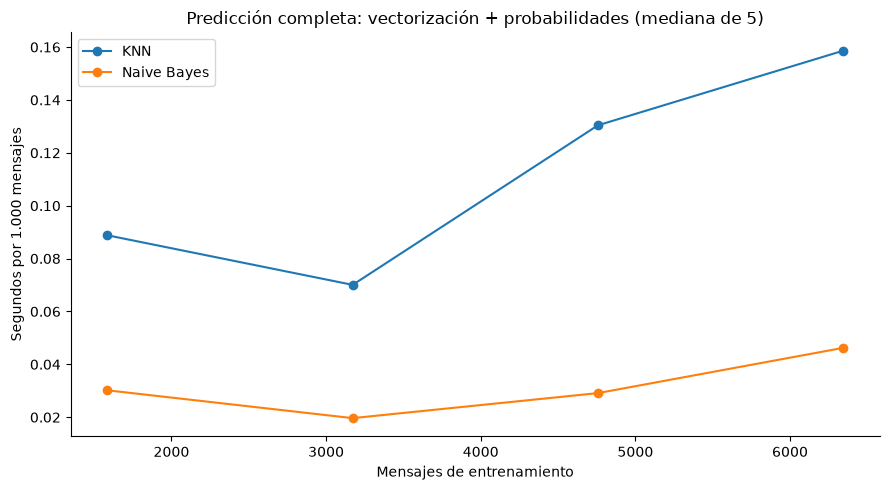

Naive Bayes consulta una tabla de términos por clase; su costo depende principalmente del vocabulario y las palabras del lote. KNN compara con los documentos almacenados y crece con el entrenamiento. Son tiempos locales sin concurrencia, red ni cola; los cinco ensayos muestran variabilidad y no constituyen un SLA de producción.

In [14]:
# Lote fijo de entrenamiento para medir velocidad sin explorar el test.
lote_1000 = X_train.sample(1000, random_state=SEMILLA).tolist()
registros_tiempo = []
for fraccion in [0.25, 0.50, 0.75, 1.00]:
    muestra = train if fraccion == 1 else train_test_split(
        train, train_size=fraccion, stratify=y_train, random_state=SEMILLA)[0]
    for nombre, modelo in modelos.items():
        ajustado = clone(modelo).fit(muestra.texto_limpio, muestra.equipo_final)
        ajustado.predict_proba(lote_1000)  # calentamiento
        tiempos = []
        for _ in range(5):
            inicio = time.perf_counter()
            ajustado.predict_proba(lote_1000)
            tiempos.append(time.perf_counter()-inicio)
        registros_tiempo.append({'modelo': nombre, 'fraccion': fraccion, 'n_train': len(muestra),
                                 'segundos_1000': float(np.median(tiempos)), 'min': min(tiempos), 'max': max(tiempos)})
tiempos = pd.DataFrame(registros_tiempo)
display(tiempos)
fig, ax = plt.subplots()
for nombre, grupo in tiempos.groupby('modelo'):
    ax.plot(grupo.n_train, grupo.segundos_1000, 'o-', label=nombre)
ax.set(xlabel='Mensajes de entrenamiento', ylabel='Segundos por 1.000 mensajes',
       title='Predicción completa: vectorización + probabilidades (mediana de 5)')
ax.legend()
fig.tight_layout(); fig.savefig(FIGURAS / 'paso12_tiempos.png', dpi=150)
plt.show()
display(Markdown('Naive Bayes consulta una tabla de términos por clase; su costo depende principalmente '
                 'del vocabulario y las palabras del lote. KNN compara con los documentos almacenados '
                 'y crece con el entrenamiento. Son tiempos locales sin concurrencia, red ni cola; '
                 'los cinco ensayos muestran variabilidad y no constituyen un SLA de producción.'))

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [15]:
pruebas('test_derivacion.py')

....                                                                     [100%]
4 passed in 0.21s



**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

,umbral_fraude,umbral_confianza,cobertura,exactitud_automatica,fraude_perdido,exactitud,f1_macro
modelo,,,,,,,
Naive Bayes,0.87,1.01,0.102932,0.970904,0.0,0.940259,0.935478
KNN,0.39,1.01,0.097888,0.971014,0.0,0.933796,0.929239


Modelo elegido antes de evaluar prueba: Naive Bayes


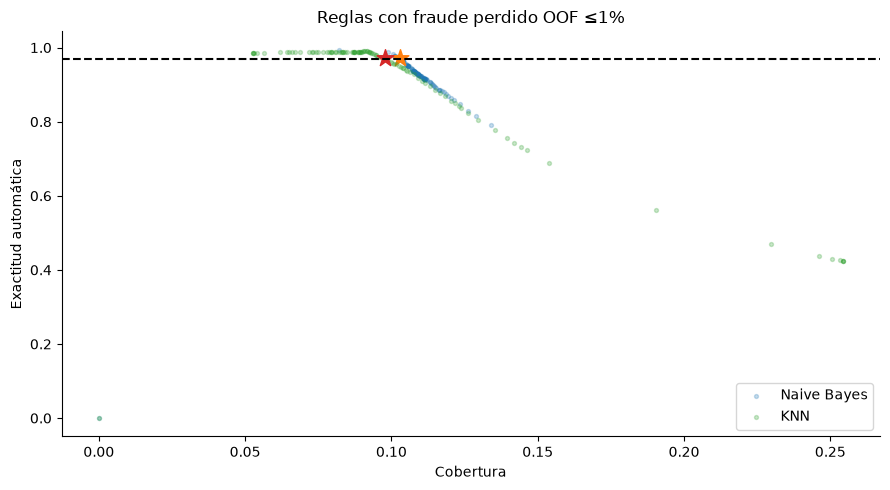

Se prioriza seguridad sobre cobertura: si la máxima cobertura segura queda bajo 70%, se declara el incumplimiento, sin relajar límites. La rejilla incluye confianzas muy cercanas a 1 por las probabilidades extremas de NB; el valor 1,01 desactiva una vía (solo fraude o solo confianza), sin confundir un umbral desactivado con una probabilidad. El margen de 2 puntos en exactitud y 1 punto en fraude es operativo, no una garantía estadística. La selección de hiperparámetros y de umbrales comparte los folds de entrenamiento: puede haber optimismo de selección. El test reservado es la auditoría final; una evaluación más estricta usaría CV anidada o un bloque temporal adicional. Las probabilidades NB no están calibradas; en KNN dependen de votos y vecinos.

In [16]:
LIMITES = {'exactitud': 0.85, 'f1_macro': 0.85, 'cobertura': 0.70,
           'exactitud_automatica': 0.95, 'fraude_perdido': 0.02}
MARGEN_EXACTITUD, MARGEN_FRAUDE = 0.97, 0.01
# Los hiperparámetros ya están fijados; cada predicción se obtiene sin entrenar con esa fila.
# El vocabulario también se aprende dentro de cada fold. No se utiliza el test.
oof, umbrales, rejillas, resumen_oof = {}, {}, {}, []
for nombre, modelo in modelos.items():
    p = cross_val_predict(clone(modelo), X_train, y_train, cv=particiones,
                          method='predict_proba', n_jobs=1)
    oof[nombre] = p
    clases = modelo.classes_
    filas = []
    for uf in np.unique(np.r_[0.001, 0.005, np.round(np.arange(0.01, 1.01, 0.01), 2), 1.01]):
        for uc in np.unique(np.r_[np.arange(0.50, 1.0, 0.01), 1-10.0**(-np.arange(3, 16)), 1.0, 1.01]):
            r = evaluar_derivacion(y_train, derivar(p, clases, uf, uc))
            filas.append({'umbral_fraude': uf, 'umbral_confianza': float(uc), **r})
    rejilla = pd.DataFrame(filas)
    factibles = rejilla.loc[(rejilla.exactitud_automatica >= MARGEN_EXACTITUD) &
                            (rejilla.fraude_perdido <= MARGEN_FRAUDE)]
    assert len(factibles), f'{nombre}: no hay regla segura; se debe mantener revisión humana'
    mejor = factibles.sort_values(['cobertura', 'fraude_perdido', 'exactitud_automatica',
                                   'umbral_fraude', 'umbral_confianza'],
                                  ascending=[False, True, False, True, False]).iloc[0]
    umbrales[nombre] = (float(mejor.umbral_fraude), float(mejor.umbral_confianza))
    rejillas[nombre] = rejilla
    resumen_oof.append({'modelo': nombre, **mejor.to_dict(),
                        'exactitud': accuracy_score(y_train, clases[p.argmax(axis=1)]),
                        'f1_macro': f1_score(y_train, clases[p.argmax(axis=1)], average='macro')})
tabla_oof = pd.DataFrame(resumen_oof).set_index('modelo')
display(tabla_oof)
# Elección antes de mirar las métricas de prueba: máxima cobertura bajo restricciones.
elegido = tabla_oof.sort_values(['cobertura', 'fraude_perdido', 'f1_macro'], ascending=[False, True, False]).index[0]
print('Modelo elegido antes de evaluar prueba:', elegido)
fig, ax = plt.subplots()
for nombre, rejilla in rejillas.items():
    seguras = rejilla.loc[rejilla.fraude_perdido <= MARGEN_FRAUDE]
    ax.scatter(seguras.cobertura, seguras.exactitud_automatica, s=8, alpha=.25, label=nombre)
    ax.scatter(tabla_oof.loc[nombre, 'cobertura'], tabla_oof.loc[nombre, 'exactitud_automatica'], marker='*', s=160)
ax.axhline(MARGEN_EXACTITUD, color='black', linestyle='--')
ax.set(xlabel='Cobertura', ylabel='Exactitud automática', title='Reglas con fraude perdido OOF ≤1%')
ax.legend(); fig.tight_layout(); fig.savefig(FIGURAS / 'paso14_umbrales.png', dpi=150); plt.show()
display(Markdown('Se prioriza seguridad sobre cobertura: si la máxima cobertura segura queda bajo 70%, '
                 'se declara el incumplimiento, sin relajar límites. La rejilla incluye confianzas muy '
                 'cercanas a 1 por las probabilidades extremas de NB; el valor 1,01 desactiva una vía '
                 '(solo fraude o solo confianza), sin confundir un umbral desactivado con una probabilidad. '
                 'El margen de 2 puntos en exactitud y 1 punto en fraude es operativo, no una garantía '
                 'estadística. La selección de hiperparámetros y de umbrales comparte los folds de entrenamiento: '
                 'puede haber optimismo de selección. El test reservado es la auditoría final; '
                 'una evaluación más estricta usaría CV anidada o un bloque temporal adicional. '
                 'Las probabilidades NB no están calibradas; en KNN dependen de votos y vecinos.'))

**Resultado de la regla conservadora.** Con los márgenes supuestos de 97% de exactitud automática y 1% de fraude perdido, la rejilla selecciona NB con `umbral_fraude=0.87` y `umbral_confianza=1.01`; para KNN son `0.39` y `1.01`. El valor 1,01 **desactiva la derivación general por confianza**: solo se automatizan avisos de fraude y el resto se revisa. La función implementa las tres salidas pedidas, pero con estos umbrales la segunda vía no se activa. La cobertura OOF es 10,29% para NB y 9,79% para KNN, por debajo del 70% supuesto. Se conserva NB como candidato para el ejercicio; **no se afirma que la automatización general sea aceptable**. El resultado es el mejor dentro de la rejilla explorada bajo esos márgenes, no una prueba de imposibilidad para cualquier modelo o política. No se relajan los requisitos tras mirar prueba.

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

,exactitud,f1_macro,cobertura,exactitud_automatica,fraude_perdido
modelo,,,,,
Naive Bayes,93.88%,93.40%,10.40%,95.76%,0.00%
KNN,92.88%,92.62%,9.84%,95.51%,0.00%
Mesa de entrada,83.54%,82.37%,100.00%,83.54%,33.52%


,exactitud,f1_macro,cobertura,exactitud_automatica,fraude_perdido
modelo,,,,,
Naive Bayes,True,True,False,True,True
KNN,True,True,False,True,True
Mesa de entrada,False,False,True,False,False


Modelo congelado: Naive Bayes ; cumple los cinco criterios: False


,precision,recall,f1-score,support
cuenta_acceso,0.929448,0.952830,0.940994,318.00000
fraude,0.926136,0.926136,0.926136,176.00000
prestamos_inversiones,0.880952,0.934343,0.906863,198.00000
tarjeta,0.947500,0.947500,0.947500,400.00000
transferencias,0.968354,0.929150,0.948347,494.00000
accuracy,0.938840,0.938840,0.938840,0.93884
macro avg,0.930478,0.937992,0.933968,1586.00000
weighted avg,0.939697,0.938840,0.939015,1586.00000


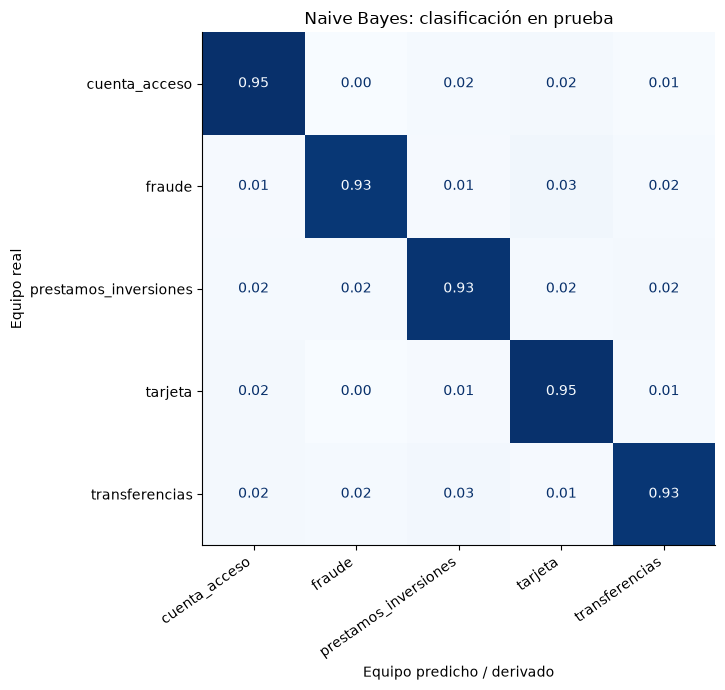

destino,fraude,revision_humana
equipo_real,,
cuenta_acceso,0.003145,0.996855
fraude,0.897727,0.102273
prestamos_inversiones,0.005051,0.994949
tarjeta,0.002500,0.997500
transferencias,0.008097,0.991903


Fraudes perdidos: 0/176; IC Wilson 95%: (np.float64(1.734723475976807e-18), np.float64(0.021361019919751596))
IC Wilson 95% de exactitud automática: (np.float64(0.9150289462090594), np.float64(0.9793004133800464))
Fraudes a revisión humana: 18


La mesa tiene cobertura de derivación del 100% porque asigna todos los casos; su trabajo sigue siendo humano. Exactitud y F1 evalúan el clasificador sin abstención; las otras tres métricas evalúan la regla. La comparación usa exactamente los mismos mensajes aptos de prueba. Los intervalos suponen observaciones independientes: las plantillas compartidas pueden volverlos optimistas. No se reajustan umbrales después de esta evaluación.

In [17]:
pred_test, proba_test, destinos_test = {}, {}, {}
resultados = []
for nombre, modelo in modelos.items():
    p = modelo.predict_proba(X_test)
    pred = modelo.classes_[p.argmax(axis=1)]
    destino = derivar(p, modelo.classes_, *umbrales[nombre])
    proba_test[nombre], pred_test[nombre], destinos_test[nombre] = p, pred, destino
    resultados.append({'modelo': nombre, 'exactitud': accuracy_score(y_test, pred),
                        'f1_macro': f1_score(y_test, pred, average='macro'),
                        **evaluar_derivacion(y_test, destino)})
resultados.append({'modelo': 'Mesa de entrada',
                    'exactitud': accuracy_score(y_test, test.equipo_derivado),
                    'f1_macro': f1_score(y_test, test.equipo_derivado, average='macro'),
                    **evaluar_derivacion(y_test, test.equipo_derivado)})
tabla_test = pd.DataFrame(resultados).set_index('modelo')
display(tabla_test.style.format('{:.2%}'))
aceptacion = tabla_test.ge(pd.Series(LIMITES))
aceptacion['fraude_perdido'] = tabla_test.fraude_perdido <= LIMITES['fraude_perdido']
display(aceptacion)
print('Modelo congelado:', elegido, '; cumple los cinco criterios:', bool(aceptacion.loc[elegido].all()))
display(pd.DataFrame(classification_report(y_test, pred_test[elegido], output_dict=True, zero_division=0)).T)
matriz(y_test, pred_test[elegido], f'{elegido}: clasificación en prueba', 'paso15_confusion.png')
display(pd.crosstab(pd.Series(y_test.to_numpy(), name='equipo_real'),
                    pd.Series(destinos_test[elegido], name='destino'), normalize='index'))

def wilson(exitos, n, z=1.96):
    if n == 0:
        return (0.0, 1.0)
    p = exitos/n
    centro = (p + z*z/(2*n))/(1+z*z/n)
    margen = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    return (centro-margen, centro+margen)

dest = destinos_test[elegido]
automatico = dest != REVISION
es_fraude = y_test.to_numpy() == 'fraude'
perdidos = automatico & es_fraude & (dest != 'fraude')
ic_fraude = wilson(int(perdidos.sum()), int(es_fraude.sum()))
ic_exactitud = wilson(int((automatico & (dest == y_test.to_numpy())).sum()), int(automatico.sum()))
print(f'Fraudes perdidos: {perdidos.sum()}/{es_fraude.sum()}; IC Wilson 95%: {ic_fraude}')
print(f'IC Wilson 95% de exactitud automática: {ic_exactitud}')
print(f'Fraudes a revisión humana: {(es_fraude & ~automatico).sum()}')
display(Markdown('La mesa tiene cobertura de derivación del 100% porque asigna todos los casos; '
                 'su trabajo sigue siendo humano. Exactitud y F1 evalúan el clasificador sin abstención; '
                 'las otras tres métricas evalúan la regla. La comparación usa exactamente los mismos mensajes aptos de prueba. '
                 'Los intervalos suponen observaciones independientes: las plantillas compartidas pueden volverlos optimistas. '
                 'No se reajustan umbrales después de esta evaluación.'))

**Lectura de la evaluación única.** NB logra 93,88% de exactitud y F1 macro de 0,9340, frente a 92,88% y 0,9262 de KNN; la mesa alcanza 83,54% de exactitud en este mismo test. La regla NB automatiza 165 de 1.586 mensajes (10,40%), con 158 aciertos (95,76%). Lleva 158 de 176 fraudes directamente a Fraude y 18 a revisión. El cero de fraude perdido es consecuencia de que solo se automatiza el destino Fraude: **no significa detección total ni ausencia de demora**. Su intervalo de Wilson llega al 2,14% y el de exactitud automática baja hasta 91,50%; tampoco hay una garantía estadística de los límites asumidos. Se recomienda mantener atención humana y evaluar el candidato en modo sombra. Además, hay 9 clientes compartidos entre particiones y 3,40% de textos de prueba ya vistos limpios: validar por cliente y fecha antes de decidir un despliegue.

**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [18]:
auditoria = test[['id_mensaje', 'texto', 'equipo_final']].copy()
auditoria['prediccion'] = pred_test[elegido]
auditoria['derivacion'] = destinos_test[elegido]
auditoria['prob_max'] = proba_test[elegido].max(axis=1)
auditoria['prob_fraude'] = proba_test[elegido][:, list(modelos[elegido].classes_).index('fraude')]
errores = auditoria.loc[(auditoria.derivacion != REVISION) & (auditoria.derivacion != auditoria.equipo_final)]
print(f'Errores automáticos: {len(errores)}')
# Hay solo 7 errores automáticos del elegido en prueba: no se inventan otros tres.
# Se completan diez casos de análisis con errores OOF del entrenamiento, identificados.
errores_prueba = errores.sort_values(['prob_max', 'id_mensaje'], ascending=[False, True]).head(10).copy()
errores_prueba['origen'] = 'prueba'
auditoria_oof = train[['id_mensaje', 'texto', 'equipo_final']].copy()
p_oof = oof[elegido]
clases_elegido = modelos[elegido].classes_
auditoria_oof['prediccion'] = clases_elegido[p_oof.argmax(axis=1)]
auditoria_oof['derivacion'] = derivar(p_oof, clases_elegido, *umbrales[elegido])
auditoria_oof['prob_max'] = p_oof.max(axis=1)
auditoria_oof['prob_fraude'] = p_oof[:, list(clases_elegido).index('fraude')]
errores_oof = auditoria_oof.loc[(auditoria_oof.derivacion != REVISION) &
                                (auditoria_oof.derivacion != auditoria_oof.equipo_final)]
extras = errores_oof.sort_values(['prob_max', 'id_mensaje'], ascending=[False, True]).head(10-len(errores_prueba)).copy()
extras['origen'] = 'entrenamiento OOF'
errores_10 = pd.concat([errores_prueba, extras], ignore_index=True)
assert len(errores_10) == 10 and errores_10.id_mensaje.is_unique
analisis = {
    'M-100820': ('El acceso sin permiso y el cambio de contraseña son señales de toma de cuenta; la etiqueta préstamos no se explica por el texto. Posible inconsistencia de etiquetado, no demostrada.',
                 'Auditar el ticket completo con Fraude y Préstamos y acordar la etiqueta de toma de cuenta. Mantener prioridad de seguridad mientras se resuelve.'),
    'M-101471': ('Hay dos intenciones: certificado de deuda e ingreso desde otro dispositivo. La regla prioriza la sospecha y la etiqueta final es cuenta_acceso.',
                 'Definir una política para mensajes multitema y crear tareas vinculadas para cuenta y fraude sin perder la alerta de seguridad.'),
    'M-106268': ('Acceso sin autorización y cambio de correo sugieren fraude, pero figura transferencias. El error ortográfico no elimina esas señales.',
                 'Verificar resolución y etiqueta; añadir ejemplos adjudicados de toma de cuenta, y anonimizar el nombre personal antes de entrenar.'),
    'M-103666': ('Un cobro que el cliente no entiende puede ser una comisión, una transferencia o una operación desconocida; la urgencia no resuelve la intención.',
                 'Solicitar tipo de operación y si la reconoce; enviar mensajes genéricos de cobro a aclaración y entrenar con ese contraste.'),
    'M-100965': ('El mensaje solo dice que hay un inconveniente con la cuenta; el texto no sustenta una decisión de fraude pese a la probabilidad alta.',
                 'Crear ejemplos de intención insuficiente y una revisión por falta de información; evaluar calibración con datos separados.'),
    'M-106750': ('Cobro no entendido es una expresión ambigua y no equivale necesariamente a desconocer una operación; la etiqueta es transferencias.',
                 'Pedir si el usuario inició la operación y distinguir comisiones, duplicados y desconocimientos en la guía de etiquetado.'),
    'M-101360': ('La frase inconveniente con mi cuenta es genérica, pero se etiqueta tarjeta. Las palabras de urgencia no identifican el producto.',
                 'Agregar una pregunta de aclaración sobre tarjeta o cuenta y recopilar casos genéricos para la ruta de revisión.'),
    'M-102274': ('La persona dice que fue estafada por teléfono, pero el destino final es préstamos. Hay una discrepancia semántica que requiere revisar el expediente.',
                 'Auditar la etiqueta con ambos equipos y documentar la prioridad de estafa telefónica; no corregir etiquetas automáticamente.'),
    'M-102770': ('El asalto y el celular con la app instalada justifican sospecha de fraude aunque se pida bloquear la cuenta; la etiqueta es transferencias.',
                 'Definir un protocolo de robo de dispositivo con bloqueo urgente y coordinación entre Fraude y Cuentas.'),
    'M-105344': ('Premio por correo, entrega de clave y compras posteriores describen phishing; la etiqueta préstamos parece incompatible con el texto visible.',
                 'Verificar la historia completa y adjudicar la etiqueta con especialistas; incorporar ejemplos revisados de phishing.'),
}
errores_10['causa_probable'] = errores_10.id_mensaje.map(lambda x: analisis[x][0])
errores_10['mejora_concreta'] = errores_10.id_mensaje.map(lambda x: analisis[x][1])
display(Markdown('Se analizan los **7 errores de prueba y 3 errores OOF** del mismo modelo con la misma regla. '
                 'Los tres OOF completan la revisión cualitativa; no se suman al numerador ni al denominador de prueba. '
                 'Las causas son hipótesis basadas en el texto, no verificaciones del ticket. No se cambian etiquetas ni umbrales.'))
display(errores_10[['id_mensaje', 'origen', 'equipo_final', 'derivacion', 'prob_fraude']])
for fila in errores_10.itertuples():
    display(Markdown(f'**{fila.id_mensaje} · {fila.origen}** — Real: `{fila.equipo_final}`; destino: `{fila.derivacion}`.\n\n'
                     f'*Mensaje:* {fila.texto}\n\n**Causa probable:** {fila.causa_probable}\n\n'
                     f'**Mejora concreta:** {fila.mejora_concreta}'))
errores_10.to_csv(BASE / 'errores_derivacion.csv', index=False)

Errores automáticos: 7


Se analizan los **7 errores de prueba y 3 errores OOF** del mismo modelo con la misma regla. Los tres OOF completan la revisión cualitativa; no se suman al numerador ni al denominador de prueba. Las causas son hipótesis basadas en el texto, no verificaciones del ticket. No se cambian etiquetas ni umbrales.

,id_mensaje,origen,equipo_final,derivacion,prob_fraude
0,M-100820,prueba,prestamos_inversiones,fraude,1.000000
1,M-101471,prueba,cuenta_acceso,fraude,1.000000
2,M-106268,prueba,transferencias,fraude,1.000000
3,M-103666,prueba,transferencias,fraude,0.998176
4,M-100965,prueba,transferencias,fraude,0.994805
5,M-106750,prueba,transferencias,fraude,0.944055
6,M-101360,prueba,tarjeta,fraude,0.895931
7,M-102274,entrenamiento OOF,prestamos_inversiones,fraude,1.000000
8,M-102770,entrenamiento OOF,transferencias,fraude,1.000000
9,M-105344,entrenamiento OOF,prestamos_inversiones,fraude,1.000000


**M-100820 · prueba** — Real: `prestamos_inversiones`; destino: `fraude`.

*Mensaje:* holaa entraron a mi cuenta sin mi permiso y cambiaron la contraseña nadie me responde

**Causa probable:** El acceso sin permiso y el cambio de contraseña son señales de toma de cuenta; la etiqueta préstamos no se explica por el texto. Posible inconsistencia de etiquetado, no demostrada.

**Mejora concreta:** Auditar el ticket completo con Fraude y Préstamos y acordar la etiqueta de toma de cuenta. Mantener prioridad de seguridad mientras se resuelve.

**M-101471 · prueba** — Real: `cuenta_acceso`; destino: `fraude`.

*Mensaje:* hola, como estan? pido un certificado de libre deuda del prestamo y ademas me llego un aviso de ingreso desde otro dispositivo y yo no fui adjunto captura necesito una solucion ya

**Causa probable:** Hay dos intenciones: certificado de deuda e ingreso desde otro dispositivo. La regla prioriza la sospecha y la etiqueta final es cuenta_acceso.

**Mejora concreta:** Definir una política para mensajes multitema y crear tareas vinculadas para cuenta y fraude sin perder la alerta de seguridad.

**M-106268 · prueba** — Real: `transferencias`; destino: `fraude`.

*Mensaje:* BUENAS TARDES, ALUGIEN ENTRÓ A MI CUENTA SIN MI PERMISO Y CAMBIARON MI MAIL. DESDE YA, GRACIAS. CARLOS BENÍTEZ

**Causa probable:** Acceso sin autorización y cambio de correo sugieren fraude, pero figura transferencias. El error ortográfico no elimina esas señales.

**Mejora concreta:** Verificar resolución y etiqueta; añadir ejemplos adjudicados de toma de cuenta, y anonimizar el nombre personal antes de entrenar.

... (3 outputs left out)

**M-101360 · prueba** — Real: `tarjeta`; destino: `fraude`.

*Mensaje:* Buenas. Tengo un inconveniente con mi cuenta. necesito la plata para hoy.

**Causa probable:** La frase inconveniente con mi cuenta es genérica, pero se etiqueta tarjeta. Las palabras de urgencia no identifican el producto.

**Mejora concreta:** Agregar una pregunta de aclaración sobre tarjeta o cuenta y recopilar casos genéricos para la ruta de revisión.

**M-102274 · entrenamiento OOF** — Real: `prestamos_inversiones`; destino: `fraude`.

*Mensaje:* hola creo que me estafaron por teléfono operación 954871458 nadie me responde

**Causa probable:** La persona dice que fue estafada por teléfono, pero el destino final es préstamos. Hay una discrepancia semántica que requiere revisar el expediente.

**Mejora concreta:** Auditar la etiqueta con ambos equipos y documentar la prioridad de estafa telefónica; no corregir etiquetas automáticamente.

**M-102770 · entrenamiento OOF** — Real: `transferencias`; destino: `fraude`.

*Mensaje:* me asaltaron y se llevaron el celular con la app instalada bloqueen mi cuenta x favor

**Causa probable:** El asalto y el celular con la app instalada justifican sospecha de fraude aunque se pida bloquear la cuenta; la etiqueta es transferencias.

**Mejora concreta:** Definir un protocolo de robo de dispositivo con bloqueo urgente y coordinación entre Fraude y Cuentas.

**M-105344 · entrenamiento OOF** — Real: `prestamos_inversiones`; destino: `fraude`.

*Mensaje:* hola cauce, recibi un mail de un supuesto premio y cargue la clave y despues me hicieron compras !!!

**Causa probable:** Premio por correo, entrega de clave y compras posteriores describen phishing; la etiqueta préstamos parece incompatible con el texto visible.

**Mejora concreta:** Verificar la historia completa y adjudicar la etiqueta con especialistas; incorporar ejemplos revisados de phishing.

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [19]:
# Extrapolación: mezcla de clases y desempeño estables; los cortos siempre se revisan.
total_dia = 6500
tasa_cortos = len(cortos)/len(datos)
r = tabla_test.loc[elegido]
automaticos_dia = total_dia*(1-tasa_cortos)*r.cobertura
revisiones_dia = total_dia-automaticos_dia
errores_dia = automaticos_dia*(1-r.exactitud_automatica)
fraude_perdido_dia = total_dia*(1-tasa_cortos)*y_test.eq('fraude').mean()*r.fraude_perdido
impacto = pd.Series({
    'mensajes_diarios': total_dia,
    'automaticos': automaticos_dia,
    'revision_humana': revisiones_dia,
    'revision_por_texto_corto': total_dia*tasa_cortos,
    'errores_automaticos': errores_dia,
    'fraudes_perdidos': fraude_perdido_dia,
    'errores_mesa_referencia': total_dia*(1-base_inicial['exactitud']),
    'carga_equivalente_personas': 9*revisiones_dia/total_dia,
})
display(impacto.round(2).to_frame('estimación_diaria'))
display(Markdown('La carga equivalente supone igual tiempo por mensaje; los casos difíciles pueden tardar más. '
                 'No implica reducción automática de personal: se puede reasignar tiempo a fraude y revisión. '
                 'Los errores de la revisión humana no están incluidos en errores automáticos. '
                 'La proyección usa el promedio histórico para textos cortos y el test para mensajes aptos.'))

,estimación_diaria
mensajes_diarios,6500.00
automaticos,670.31
revision_humana,5829.69
revision_por_texto_corto,56.88
errores_automaticos,28.44
fraudes_perdidos,0.00
errores_mesa_referencia,1130.37
carga_equivalente_personas,8.07


La carga equivalente supone igual tiempo por mensaje; los casos difíciles pueden tardar más. No implica reducción automática de personal: se puede reasignar tiempo a fraude y revisión. Los errores de la revisión humana no están incluidos en errores automáticos. La proyección usa el promedio histórico para textos cortos y el test para mensajes aptos.

**Interpretación del impacto.** La regla conservadora proyecta aproximadamente **670 derivaciones automáticas y 5.830 revisiones diarias**, con 28 errores automáticos, todos falsos avisos de fraude. La carga de revisión equivale a unas 8,1 personas bajo el supuesto simplificador de igual tiempo por mensaje. El beneficio sería acotado y centrado en priorizar sospechas de fraude; no resuelve todavía el reparto masivo entre los cinco equipos. El cero proyectado de fraudes enviados automáticamente a otro equipo es estructural en esta regla; no elimina el riesgo de espera en la cola humana.

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [20]:
final = clone(modelos[elegido]).fit(aptos.texto_limpio, aptos.equipo_final)
nuevos = pd.read_csv(BASE / 'datos/mensajes_nuevos.csv')
nuevos_limpios = nuevos.texto.map(limpiar_texto)
nuevos_cortos = nuevos_limpios.str.split().str.len().lt(2).to_numpy()
p_nuevos = final.predict_proba(nuevos_limpios)
destinos_nuevos = derivar(p_nuevos, final.classes_, *umbrales[elegido])
destinos_nuevos[nuevos_cortos] = REVISION
print(f'Modelo final: {elegido}; entrenado con {len(aptos)} mensajes; umbrales conservados: {umbrales[elegido]}')
print(f'Nuevos cortos a revisión obligatoria: {nuevos_cortos.sum()}')
display(pd.Series(destinos_nuevos).value_counts().to_frame('mensajes_nuevos'))
display(Markdown('Para textos cortos se conservan las probabilidades técnicas del modelo en el archivo, '
                 'pero no se usan para automatizar. Su equipo_predicho no equivale a un destino aprobado. '
                 'La regla de longitud tiene prioridad sobre cualquier probabilidad.'))

Modelo final: Naive Bayes; entrenado con 7930 mensajes; umbrales conservados: (0.87, 1.01)
Nuevos cortos a revisión obligatoria: 15


,mensajes_nuevos
revision_humana,1815
fraude,225


Para textos cortos se conservan las probabilidades técnicas del modelo en el archivo, pero no se usan para automatizar. Su equipo_predicho no equivale a un destino aprobado. La regla de longitud tiene prioridad sobre cualquier probabilidad.

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [21]:
salida = pd.DataFrame({
    'id_mensaje': nuevos.id_mensaje,
    'equipo_predicho': final.classes_[p_nuevos.argmax(axis=1)],
    'prob_max': p_nuevos.max(axis=1),
    'prob_fraude': p_nuevos[:, list(final.classes_).index('fraude')],
    'derivacion': destinos_nuevos,
})
ruta_salida = BASE / 'predicciones_caso1.csv'
salida.to_csv(ruta_salida, index=False, float_format='%.12g')
verificada = pd.read_csv(ruta_salida)
assert verificada.shape == (2040, 5)
assert verificada.columns.tolist() == ['id_mensaje', 'equipo_predicho', 'prob_max', 'prob_fraude', 'derivacion']
assert verificada.id_mensaje.is_unique and verificada.id_mensaje.equals(nuevos.id_mensaje)
assert not verificada.isna().any().any()
assert verificada[['prob_max', 'prob_fraude']].ge(0).all().all()
assert verificada[['prob_max', 'prob_fraude']].le(1).all().all()
assert set(verificada.equipo_predicho) <= set(CLASES)
assert set(verificada.derivacion) <= set(CLASES) | {REVISION}
assert (verificada.loc[nuevos_cortos, 'derivacion'] == REVISION).all()
print(f'Formato verificado: {verificada.shape[0]} filas, {verificada.shape[1]} columnas.')
display(verificada.head())
resumen = {
    'modelo_elegido': elegido, 'limites_asumidos': LIMITES, 'umbrales': umbrales,
    'mejores_parametros': {'Naive Bayes': busqueda_nb.best_params_, 'KNN': busqueda_knn.best_params_},
    'historicos': len(historico), 'deduplicados': len(datos), 'cortos': len(cortos),
    'train': len(train), 'test': len(test), 'coincidencia_sklearn': coincidencia,
    'oof': tabla_oof.reset_index().to_dict('records'),
    'test_resultados': tabla_test.reset_index().to_dict('records'),
    'aceptacion': bool(aceptacion.loc[elegido].all()),
    'ic_fraude': ic_fraude, 'ic_exactitud': ic_exactitud,
    'fraudes_test': int(es_fraude.sum()), 'fraudes_perdidos_test': int(perdidos.sum()),
    'fraudes_revision_test': int((es_fraude & ~automatico).sum()),
    'tiempos': tiempos.to_dict('records'), 'impacto': impacto.to_dict(),
    'nuevos_destinos': salida.derivacion.value_counts().to_dict(),
    'nuevos_cortos': int(nuevos_cortos.sum()),
}
(BASE / 'resultados_caso1.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')

Formato verificado: 2040 filas, 5 columnas.


,id_mensaje,equipo_predicho,prob_max,prob_fraude,derivacion
0,M-300001,transferencias,1.0,4.600195e-18,revision_humana
1,M-300002,transferencias,1.0,5.422874e-13,revision_humana
2,M-300003,transferencias,1.0,2.687840e-28,revision_humana
3,M-300004,transferencias,1.0,2.687840e-28,revision_humana
4,M-300005,tarjeta,1.0,6.658106e-37,revision_humana


4379

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

El informe se entrega en [informe_ejecutivo.pdf](informe_ejecutivo.pdf). Se genera a partir de `resultados_caso1.json` con `crear_informe.py` (requiere ReportLab). Los gráficos y el CSV se regeneran al ejecutar este notebook. El informe distingue los supuestos de aceptación de los resultados medidos y propone un piloto supervisado.

El informe se entrega en [informe_ejecutivo.pdf](informe_ejecutivo.pdf). Se genera a partir de `resultados_caso1.json` con `crear_informe.py` (requiere ReportLab). Los gráficos y el CSV se regeneran al ejecutar este notebook. El informe distingue los supuestos de aceptación de los resultados medidos y propone un piloto supervisado.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

**Respuesta.** La independencia condicional simplifica la estimación: aunque las palabras estén relacionadas, muchas aportan evidencia en la misma dirección y el orden de las clases puede seguir siendo correcto. La equivalencia del paso 8 verifica la implementación, no la validez de la suposición. Repeticiones y palabras correlacionadas pueden contar evidencia varias veces y producir probabilidades demasiado extremas; por eso no interpretamos 0,99 como una garantía del 99%. Los umbrales se eligen con predicciones fuera de muestra y se auditan en prueba; antes de producción evaluaría calibración en un bloque independiente.**Respuesta.** La independencia condicional simplifica la estimación: aunque las palabras estén relacionadas, muchas aportan evidencia en la misma dirección y el orden de las clases puede seguir siendo correcto. La equivalencia del paso 8 verifica la implementación, no la validez de la suposición. Repeticiones y palabras correlacionadas pueden contar evidencia varias veces y producir probabilidades demasiado extremas; por eso no interpretamos 0,99 como una garantía del 99%. Los umbrales se eligen con predicciones fuera de muestra y se auditan en prueba; antes de producción evaluaría calibración en un bloque independiente.

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

**Respuesta.** Si la palabra pertenece al vocabulario pero nunca apareció en fraude, alpha=0 asignaría P(palabra|fraude)=0 y una sola aparición anularía la probabilidad conjunta de fraude. En logaritmos aparece -infinito y pueden surgir operaciones indefinidas. El suavizado aditivo evita ese veto. Si la palabra es completamente nueva para el vocabulario, CountVectorizer la ignora: es un problema distinto que se debe vigilar. La implementación exige alpha positivo y la búsqueda compara 0,1; 0,5; 1 y 2.**Respuesta.** Si la palabra pertenece al vocabulario pero nunca apareció en fraude, alpha=0 asignaría P(palabra|fraude)=0 y una sola aparición anularía la probabilidad conjunta de fraude. En logaritmos aparece -infinito y pueden surgir operaciones indefinidas. El suavizado aditivo evita ese veto. Si la palabra es completamente nueva para el vocabulario, CountVectorizer la ignora: es un problema distinto que se debe vigilar. La implementación exige alpha positivo y la búsqueda compara 0,1; 0,5; 1 y 2.

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

**Respuesta.** equipo_derivado representa una decisión previa de la mesa y no estaría disponible al recibir un mensaje antes de repartirlo. Usarlo incorporaría información posterior al punto de decisión, además de reproducir errores humanos. En este caso sirve exclusivamente como línea base; equipo_final es la etiqueta supervisada. Si existiera una etapa posterior de corrección automática sería otro problema, con otro contrato de variables y evaluación.**Respuesta.** equipo_derivado representa una decisión previa de la mesa y no estaría disponible al recibir un mensaje antes de repartirlo. Usarlo incorporaría información posterior al punto de decisión, además de reproducir errores humanos. En este caso sirve exclusivamente como línea base; equipo_final es la etiqueta supervisada. Si existiera una etapa posterior de corrección automática sería otro problema, con otro contrato de variables y evaluación.

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

**Respuesta.** KNN conserva documentos vectorizados y debe comparar cada consulta con ellos, aumentando memoria y tiempo al crecer el histórico. Naive Bayes guarda conteos o probabilidades por término y clase y predice mediante una suma ponderada. El paso 12 mide ambos pipelines con el mismo lote de 1.000 mensajes y cinco repeticiones. Elegiría KNN si su mejora de cobertura y seguridad compensara el costo medido, o si mostrar casos similares aportara valor al operador; la decisión del caso se fija con la validación y se verifica una vez en prueba.**Respuesta.** KNN conserva documentos vectorizados y debe comparar cada consulta con ellos, aumentando memoria y tiempo al crecer el histórico. Naive Bayes guarda conteos o probabilidades por término y clase y predice mediante una suma ponderada. El paso 12 mide ambos pipelines con el mismo lote de 1.000 mensajes y cinco repeticiones. Elegiría KNN si su mejora de cobertura y seguridad compensara el costo medido, o si mostrar casos similares aportara valor al operador; la decisión del caso se fija con la validación y se verifica una vez en prueba.

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

**Respuesta.** Laura Benítez, Operaciones y los responsables de Fraude deben acordar los límites, con aportes de Riesgo y cumplimiento cuando corresponda. Datos debe presentar curvas de cobertura versus errores, falsos avisos de fraude, volumen de revisión, tiempos de atención e incertidumbre estadística, además del costo de cada error. Aquí 95% de exactitud automática y 2% de fraude perdido son supuestos explícitos; el margen de validación es 97% y 1%. El intervalo de Wilson del paso 15 muestra por qué cumplir un valor puntual no garantiza el mismo resultado en producción.**Respuesta.** Laura Benítez, Operaciones y los responsables de Fraude deben acordar los límites, con aportes de Riesgo y cumplimiento cuando corresponda. Datos debe presentar curvas de cobertura versus errores, falsos avisos de fraude, volumen de revisión, tiempos de atención e incertidumbre estadística, además del costo de cada error. Aquí 95% de exactitud automática y 2% de fraude perdido son supuestos explícitos; el margen de validación es 97% y 1%. El intervalo de Wilson del paso 15 muestra por qué cumplir un valor puntual no garantiza el mismo resultado en producción.

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

**Respuesta.** Un seguro introduce vocabulario e intenciones nuevos, posiblemente una clase que no existe entre los cinco equipos actuales. El modelo cerrado asignará algún equipo conocido y puede hacerlo con confianza alta. Vigilaría palabras fuera del vocabulario, proporción de textos sin términos reconocidos, revisión humana, cambios por canal y errores por producto en muestras etiquetadas. Acordaría el destino del nuevo producto, recopilaría ejemplos y reentrenaría con evaluación temporal; un aumento de confianza por sí solo no demuestra calidad.**Respuesta.** Un seguro introduce vocabulario e intenciones nuevos, posiblemente una clase que no existe entre los cinco equipos actuales. El modelo cerrado asignará algún equipo conocido y puede hacerlo con confianza alta. Vigilaría palabras fuera del vocabulario, proporción de textos sin términos reconocidos, revisión humana, cambios por canal y errores por producto en muestras etiquetadas. Acordaría el destino del nuevo producto, recopilaría ejemplos y reentrenaría con evaluación temporal; un aumento de confianza por sí solo no demuestra calidad.

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

**Respuesta.** Anonimizaría nombres, DNI, teléfonos, correos, direcciones, números de tarjeta o cuenta, CBU/CVU y enlaces que identifiquen personas; separaría identificadores de cliente en una tabla de acceso restringido si se necesitan para deduplicar o agrupar. La limpieza implementada reemplaza números, montos, correos y URL, pero no elimina de forma completa nombres ni direcciones y los CSV originales siguen conteniendo información identificable. Los marcadores preservan señales semánticas y reducen sobreajuste; al retirar dominios o patrones relevantes de estafas puede perderse información, por lo que evaluaría señales agregadas que no identifiquen personas.**Respuesta.** Anonimizaría nombres, DNI, teléfonos, correos, direcciones, números de tarjeta o cuenta, CBU/CVU y enlaces que identifiquen personas; separaría identificadores de cliente en una tabla de acceso restringido si se necesitan para deduplicar o agrupar. La limpieza implementada reemplaza números, montos, correos y URL, pero no elimina de forma completa nombres ni direcciones y los CSV originales siguen conteniendo información identificable. Los marcadores preservan señales semánticas y reducen sobreajuste; al retirar dominios o patrones relevantes de estafas puede perderse información, por lo que evaluaría señales agregadas que no identifiquen personas.